<a href="https://colab.research.google.com/github/Yasser-Baleghi/hands-on-dl-image-processing/blob/master/chapter_10/10_denoising_color.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================
# Chapter 10.7: Color Denoising on BSDS500
# ============================================
import os
import time
import random
import subprocess
import shutil
import numpy as np
import matplotlib.pyplot as plt
import cv2
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, Concatenate, BatchNormalization, Activation
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

%matplotlib inline
print(f"✅ TensorFlow version: {tf.__version__}")

✅ TensorFlow version: 2.21.0


In [2]:
# ============================================
# Download BSDS500 (using GitHub mirror)
# ============================================
DATASET_REPO = "https://github.com/BIDS/BSDS500.git"
CLONE_DIR = "BSDS500_repo"

if not os.path.exists(CLONE_DIR):
    print("Cloning BSDS500 dataset...")
    subprocess.run(['git', 'clone', '--depth', '1', DATASET_REPO, CLONE_DIR], check=True)
    print("Clone successful.")
else:
    print("Dataset already exists.")

BASE_DIR = os.path.join(CLONE_DIR, "BSDS500", "data", "images")
TRAIN_DIR = os.path.join(BASE_DIR, "train")
VAL_DIR   = os.path.join(BASE_DIR, "val")
TEST_DIR  = os.path.join(BASE_DIR, "test")
print(f"Dataset paths set.")

Cloning BSDS500 dataset...
Clone successful.
Dataset paths set.


In [3]:
# ============================================
# Helper Functions
# ============================================
PATCH_SIZE = 64
STRIDE = 64

def load_image_color(path):
    """Load a color image as float32 in [0,1]."""
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
    return img

def get_image_paths(directory):
    return [os.path.join(directory, f) for f in os.listdir(directory) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

def extract_patches_from_directory(directory, max_images=None):
    paths = get_image_paths(directory)
    if max_images:
        paths = paths[:max_images]
    all_patches = []
    for i, p in enumerate(paths):
        if i % 50 == 0:
            print(f"  Processing {i+1}/{len(paths)} ...")
        img = load_image_color(p)
        h, w, _ = img.shape
        for y in range(0, h - PATCH_SIZE + 1, STRIDE):
            for x in range(0, w - PATCH_SIZE + 1, STRIDE):
                patch = img[y:y+PATCH_SIZE, x:x+PATCH_SIZE, :]
                all_patches.append(patch)
    return np.array(all_patches, dtype=np.float32)

In [4]:
# ============================================
# Build CNN Denoiser for Color Images
# ============================================
def build_cnn_denoiser(input_shape=(PATCH_SIZE, PATCH_SIZE, 3)):
    inputs = Input(shape=input_shape)
    x = Conv2D(64, (3,3), activation='relu', padding='same')(inputs)
    x = Conv2D(64, (3,3), activation='relu', padding='same')(x)
    x = Conv2D(64, (3,3), activation='relu', padding='same')(x)
    x = Conv2D(64, (3,3), activation='relu', padding='same')(x)
    outputs = Conv2D(3, (3,3), activation='sigmoid', padding='same')(x)
    model = Model(inputs, outputs)
    model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])
    return model

cnn_color = build_cnn_denoiser()
cnn_color.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 3)      │         1,731 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,307 (446.51 KB)

 Trainable params: 114,307 (446.51 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# ============================================
# Prepare Data and Train
# ============================================
print("Extracting training patches...")
train_patches = extract_patches_from_directory(TRAIN_DIR)
print(f"Train patches: {train_patches.shape[0]}")

print("Extracting validation patches...")
val_patches = extract_patches_from_directory(VAL_DIR)
print(f"Val patches: {val_patches.shape[0]}")

def create_dataset(patches, sigma=0.1, batch_size=32, shuffle=True):
    ds = tf.data.Dataset.from_tensor_slices(patches)
    def add_noise(patch):
        noise = tf.random.normal(tf.shape(patch), mean=0.0, stddev=sigma)
        noisy = tf.clip_by_value(patch + noise, 0.0, 1.0)
        return noisy, patch
    ds = ds.map(add_noise, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=10000)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = create_dataset(train_patches, sigma=0.1, batch_size=32, shuffle=True)
val_ds   = create_dataset(val_patches, sigma=0.1, batch_size=32, shuffle=False)

EPOCHS = 20
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
]

print("Training color CNN denoiser...")
start = time.time()
history = cnn_color.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)
print(f"Training completed in {time.time() - start:.1f} s")

Extracting training patches...
  Processing 1/200 ...
  Processing 51/200 ...
  Processing 101/200 ...
  Processing 151/200 ...
Train patches: 7000
Extracting validation patches...
  Processing 1/100 ...
  Processing 51/100 ...
Val patches: 3500
Training color CNN denoiser...
Epoch 1/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 24s 61ms/step - loss: 0.0086 - mae: 0.0601 - val_loss: 0.0022 - val_mae: 0.0348 - learning_rate: 0.0010
Epoch 2/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - loss: 0.0017 - mae: 0.0310 - val_loss: 0.0017 - val_mae: 0.0308 - learning_rate: 0.0010
Epoch 3/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - loss: 0.0015 - mae: 0.0290 - val_loss: 0.0014 - val_mae: 0.0287 - learning_rate: 0.0010
Epoch 4/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 10s 35ms/step - loss: 0.0014 - mae: 0.0279 - val_loss: 0.0015 - val_mae: 0.0289 - learning_rate: 0.0010
Epoch 5/20
219/219 ━━━━━━━━━━━━━━━━━━━━ 10s 36ms/step - loss: 0.0013 - mae: 0.0271 - val_loss: 0.0014 - val_mae: 0.0280 - learning_rate: 0.0010
Epoc

Denoising...


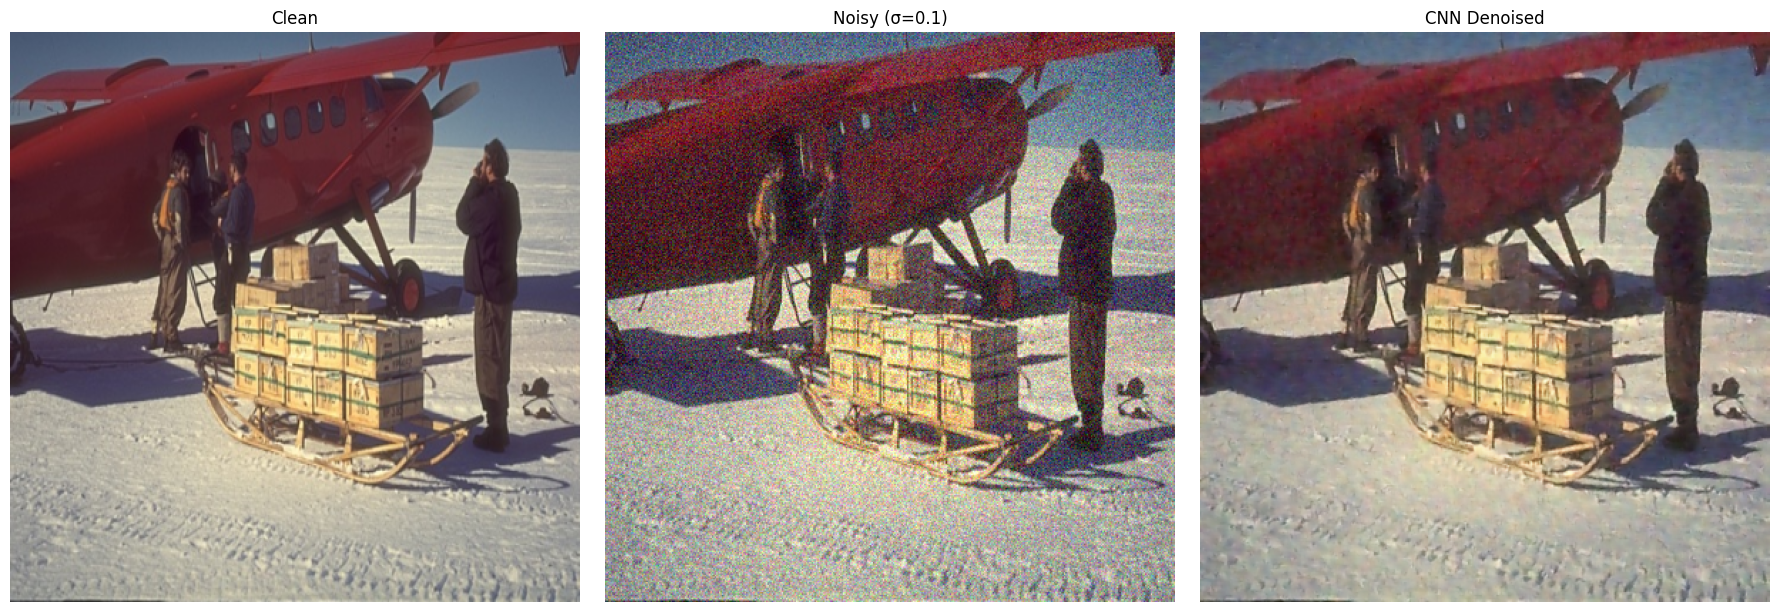

Noisy PSNR: 20.11 dB
Denoised PSNR: 30.78 dB


In [6]:
# ============================================
# Denoise a Full High-Resolution Test Image
# ============================================
def denoise_image_patches_color(model, image, patch_size=PATCH_SIZE, stride=32):
    h, w, c = image.shape
    pad_h = (patch_size - h % patch_size) % patch_size
    pad_w = (patch_size - w % patch_size) % patch_size
    padded = np.pad(image, ((0, pad_h), (0, pad_w), (0,0)), mode='reflect')
    ph, pw, _ = padded.shape

    output = np.zeros((ph, pw, 3))
    weights = np.zeros((ph, pw))

    center = patch_size // 2
    y_idx, x_idx = np.ogrid[:patch_size, :patch_size]
    dist = np.sqrt((y_idx - center)**2 + (x_idx - center)**2)
    weight_matrix = np.exp(-dist / (patch_size / 4))

    for i in range(0, ph - patch_size + 1, stride):
        for j in range(0, pw - patch_size + 1, stride):
            patch = padded[i:i+patch_size, j:j+patch_size, :]
            patch_input = patch.reshape(1, patch_size, patch_size, 3)
            denoised = model.predict(patch_input, verbose=0)[0]

            for ch in range(3):
                output[i:i+patch_size, j:j+patch_size, ch] += denoised[:,:,ch] * weight_matrix
            weights[i:i+patch_size, j:j+patch_size] += weight_matrix

    for ch in range(3):
        output[:,:,ch] = output[:,:,ch] / (weights + 1e-8)

    return output[:h, :w, :]

# Use a high-resolution color image from the test set
test_images = get_image_paths(TEST_DIR)
test_image_path = random.choice(test_images)
clean_img = load_image_color(test_image_path)
# Resize to a reasonable size for display (e.g., 400x400)
clean_img = cv2.resize(clean_img, (400, 400))
noisy_img = np.clip(clean_img + np.random.normal(0, 0.1, clean_img.shape), 0, 1)

print("Denoising...")
denoised_img = denoise_image_patches_color(cnn_color, noisy_img)

# Display
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(clean_img); axes[0].set_title('Clean'); axes[0].axis('off')
axes[1].imshow(noisy_img); axes[1].set_title('Noisy (σ=0.1)'); axes[1].axis('off')
axes[2].imshow(denoised_img); axes[2].set_title('CNN Denoised'); axes[2].axis('off')
plt.tight_layout()
plt.show()

# Metrics
psnr_noisy = peak_signal_noise_ratio(clean_img, noisy_img, data_range=1.0)
psnr_denoised = peak_signal_noise_ratio(clean_img, denoised_img, data_range=1.0)
print(f"Noisy PSNR: {psnr_noisy:.2f} dB")
print(f"Denoised PSNR: {psnr_denoised:.2f} dB")